In [50]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
pd.set_option('display.max_rows', 10)
pd.set_option('display.min_rows', 6)

In [51]:
X = pd.read_csv('application_train.csv')
X = X.set_index('SK_ID_CURR')
X

,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
SK_ID_CURR,,,,,,,,,,,,,,,,,,,,,
100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
456253,0,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,585000.0,...,0,0,0,0,1.0,0.0,0.0,1.0,0.0,1.0
456254,1,Cash loans,F,N,Y,0,171000.0,370107.0,20205.0,319500.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
456255,0,Cash loans,F,N,N,0,157500.0,675000.0,49117.5,675000.0,...,0,0,0,0,0.0,0.0,0.0,2.0,0.0,1.0


# Data transformation and pipelines

In [52]:
"""
We apply the following transformation policy:
Numeric data is imputed via medians
Obj data with k=2 categories is encoder ordinally
Obj data with k>2 categories is encoded with OH encoding
"""

y = X['TARGET']
X = X.drop(columns=['TARGET']) 

cat = X.select_dtypes(exclude='number')
ORD_COLS = [c for c in cat.columns if cat[c].fillna('Missing').nunique() <= 2]
OH_COLS  = [c for c in cat.columns if cat[c].fillna('Missing').nunique() > 2]
NUM_COLS = list(X.select_dtypes(include='number').columns)  

In [53]:
# PIPELINE INCLUDING PREPROCESSING AND MODEL
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

def build_pipeline(model):  # Reads the fixed columns from X, no possible leakage
    numeric_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', MinMaxScaler(feature_range=(0, 1))),
    ])
    ord_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('encoder', OrdinalEncoder()),
    ])
    oh_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])
    preprocess = ColumnTransformer([
        ('num', numeric_pipe, NUM_COLS),
        ('ord', ord_pipe, ORD_COLS),
        ('oh',  oh_pipe,  OH_COLS),
    ])

    pipe = Pipeline([('preprocess', preprocess), ('model', model)])

    X_transformed = preprocess.fit_transform(X)
    oh_names = preprocess.named_transformers_['oh'].named_steps['encoder'].get_feature_names_out(OH_COLS)
    feature_names = NUM_COLS + ORD_COLS + list(oh_names)
    X_transformed = pd.DataFrame(X_transformed, columns=feature_names, index=X.index)

    return pipe, X_transformed

In [54]:
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.metrics import roc_auc_score

def model_eval(pipe, df):

    predicts = cross_val_predict(pipe, df, y, cv=5, method='predict_proba')
    roc = roc_auc_score(y, predicts[:, 1])   # one pooled AUC over all out-of-fold predictions
    pred_df = pd.DataFrame(predicts, columns=['P(no_default)', 'P(default)'], index=y.index)
    pred_df['TARGET'] = y.values

    fig, ax = plt.subplots(figsize=(8, 5))
    sns.kdeplot(data=pred_df, x='P(default)', hue='TARGET', common_norm=False, fill=True, alpha=0.3, ax=ax)
    ax.set_xlabel('Predicted P(default)')
    ax.set_title('Predicted probability distribution by true class')
    ax.grid(True, linestyle='--', alpha=0.4)
    plt.show()

    print(f'AUC score on CV: {roc}')
    print('------------------------------')
    print(pred_df.head())

# Initial model exploration
NOTE THE IMPORTANCE OF class_weight='balanced'

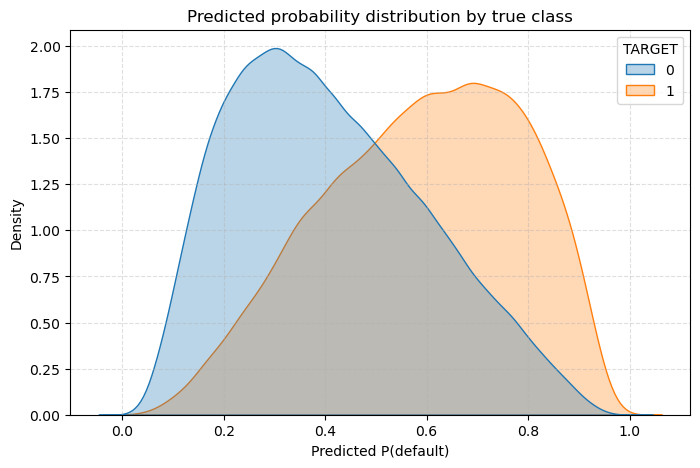

AUC score on CV: 0.7453677125871208
------------------------------
            P(no_default)  P(default)  TARGET
SK_ID_CURR                                   
100002           0.051570    0.948430       1
100003           0.752387    0.247613       0
100004           0.743592    0.256408       0
100006           0.576096    0.423904       0
100007           0.511547    0.488453       0


In [55]:
from sklearn.linear_model import LogisticRegression

"""
 ─────────────────────────────────────────────────────────────────────────
 HOW `pipe` WORKS  (pipe = Pipeline([('preprocess', ...), ('model', ...)]))

 pipe.fit(X, y):
   1. preprocess.fit_transform(X)   -> LEARNS median/categories/min-max
                                        from X, AND transforms X using them
   2. model.fit(X_transformed, y)   -> LEARNS model params (coefs/splits/etc.)
                                        from the transformed data

 pipe.predict(Z)  /  pipe.predict_proba(Z):
   1. preprocess.transform(Z)       -> APPLIES the median/categories/min-max
                                        already learned during .fit() --
                                        does NOT relearn anything from Z
   2. model.predict(Z_transformed)  -> APPLIES the model params already
                                        learned during .fit()

   => .predict()/.predict_proba() never fit anything. Always call .fit()
      first, on raw training data, before predicting on anything.
    --      --      --      --      --      --      --      --      --    
 Rule of thumb:
   .fit() / cross_val_score() / GridSearchCV(...).fit()  -> always raw X, y
   .predict() / .predict_proba() / .transform()          -> always raw data
   (X_transformed, the standalone preprocessed snapshot, never goes back
   into pipe -- it's for inspection/plotting only.)
 ─────────────────────────────────────────────────────────────────────────
"""

pipe, X_train = build_pipeline(LogisticRegression(class_weight='balanced', max_iter=500)) # NOTE class_weight='balanced'

model_eval(pipe, X)

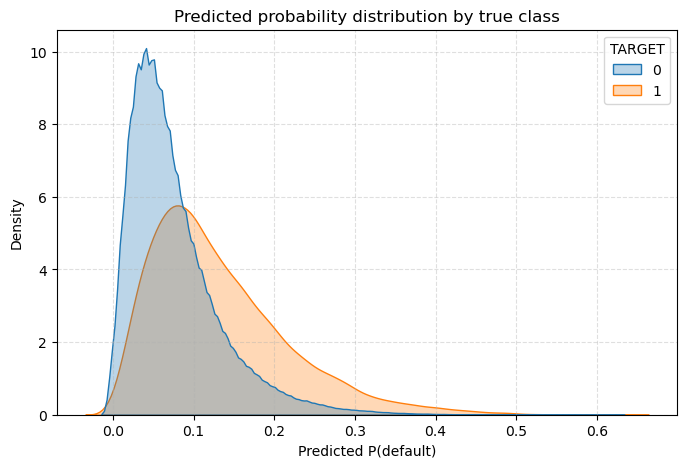

AUC score on CV: 0.7188091880707669
------------------------------
            P(no_default)  P(default)  TARGET
SK_ID_CURR                                   
100002               0.59        0.41       1
100003               0.93        0.07       0
100004               0.98        0.02       0
100006               0.90        0.10       0
100007               0.80        0.20       0


In [56]:
# Random forest

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, class_weight='balanced_subsample', random_state=50, n_jobs=-1)
pipe, X_train = build_pipeline(rf)

model_eval(pipe, X)

With no extra features or feature engineering and with simple imputing/encoding we get:

Logistic: AUC = 0.7453; and an easy to distinguish distributions

Random Forest: AUC = 0.7188; and hard to distinguish distributions with similar centers.

In [ ]:
# Read and store additional csv's with extra features

"""
NOTE: The index 'SK_ID_CURR' is not unique in the suplementary CSV's
so we have to groupby after taking only the relevant indexes from the clients in "X".
"""

bureau = pd.read_csv('bureau.csv')
bureau = bureau[bureau['SK_ID_CURR'].isin(X.index)].set_index('SK_ID_CURR')


ccb = pd.read_csv('credit_card_balance.csv')
ccb = ccb[ccb['SK_ID_CURR'].isin(X.index)].set_index('SK_ID_CURR')


install_pay = pd.read_csv('installments_payments.csv')
install_pay = install_pay[install_pay['SK_ID_CURR'].isin(X.index)].set_index('SK_ID_CURR')

bureau_bal = pd.read_csv('bureau_balance.csv') # DOES NOT HAVE THE index column from others
bureau_bal.sort

2.5159874502139137